# Task-transfer — figure & table generator (q-transfer + kv-transfer)

Reproduces the paper's DIFF task-transfer appendix charts + grids (`task_transfer.tex`), for
**250 goal heads, alpha=2**, on `Qwen2.5-Coder-32B-Instruct`.

Arms selected (see report / notebook 04.1, 05.1, 15):
- **q-transfer** = the *diff-trigger* setup (order-matched vs order-diff), no `--attn_restrict`
  (the reported primary; restrict is only an ablation): `diff_trigger/ph-goal_250__a2__piv-eq/{order_matched,order_diff}`.
- **kv-transfer** = the multi-predicate setup, no ablation:
  `kv_transfer/multi_pred/ph-goal_250__ro-goal_250__abl-off__a2__pad`.

Metrics: `causal_trigger_rate` (causal-shift, SOLID) and `readout_shift_rate` (readout-shift, HATCHED).
Saves PDFs + .tex to `notebooks/Figures/transfer/`.

**2026-09-29:** order-diff reads the sequential-naming re-run (`…piv-eq__seq/order_diff`); order-matched is unchanged.

In [1]:
import os, sys
_d=os.getcwd()
while _d!='/' and not os.path.isdir(os.path.join(_d,'src')): _d=os.path.dirname(_d)
sys.path.insert(0,_d); os.chdir(_d)
from src.utils import env_utils
sys.path.insert(0, os.path.join(env_utils.PROJECT_ROOT,'notebooks','fig_n_table_generators'))

In [2]:
import os, json
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.patches import Patch
import figstyle as F; F.set_style()
from rich import print as rich_print
from rich.table import Table

GROUP = 'transfer'
MODEL = 'Qwen2.5-Coder-32B-Instruct'
DIFF  = os.path.join(env_utils.DEFAULT_RESULTS_DIR, 'diff', MODEL)

# selected arms (250 heads, alpha=2) --------------------------------------------------
Q_ARM  = os.path.join(DIFF, 'diff_trigger', 'ph-goal_250__a2__piv-eq')          # no --attn_restrict (primary)
# order-diff re-run with SEQUENTIAL letter naming (data._seq_letter, 2026-09-29); order-matched prompts are
# naming-independent (in-order prefill), so they stay in the original arm.
Q_ARMS = {'order_matched': Q_ARM, 'order_diff': Q_ARM + '__seq'}
KV_ARM = os.path.join(DIFF, 'kv_transfer', 'multi_pred',
                      'ph-goal_250__ro-goal_250__abl-off__a2__pad')             # no ablation

COLOR = F.MODEL_COLOR[MODEL]

# axes (display order) ----------------------------------------------------------------
DTS   = ['int', 'str', 'list[int]', 'list[str]']
LANGS = ['python-python', 'python-cpp', 'cpp-python', 'cpp-cpp']
DT_LBL   = {'int':'int','str':'str','list[int]':'list[int]','list[str]':'list[str]'}
LANG_LBL = {'python-python':'py$\\to$py','python-cpp':'py$\\to$cpp',
            'cpp-python':'cpp$\\to$py','cpp-cpp':'cpp$\\to$cpp'}
# datatype dir-token spelling differs per pipeline
Q_DT  = {'int':'int','str':'str','list[int]':'list(int)','list[str]':'list(str)'}
KV_DT = {'int':'int','str':'str','list[int]':'list_int','list[str]':'list_str'}

def _read(path):
    d = json.load(open(path)); return d[0] if isinstance(d, list) else d

def load_q(variant, dt, lang):
    e = _read(os.path.join(Q_ARMS[variant], variant, f'{Q_DT[dt]}__{lang}', 'summary.json'))
    return e['causal_trigger_rate'], e['readout_shift_rate'], e.get('n')

def load_kv(dt, lang):
    e = _read(os.path.join(KV_ARM, f'{KV_DT[dt]}__letters__var_eq__{lang}', 'meta.json'))
    return e['causal_trigger_rate'], e['readout_shift_rate'], e.get('n_instances')

print('q  arms:', {v: os.path.relpath(a, DIFF) for v, a in Q_ARMS.items()})
print('kv arm:', os.path.relpath(KV_ARM, DIFF))

q  arms: {'order_matched': 'diff_trigger/ph-goal_250__a2__piv-eq', 'order_diff': 'diff_trigger/ph-goal_250__a2__piv-eq__seq'}
kv arm: kv_transfer/multi_pred/ph-goal_250__ro-goal_250__abl-off__a2__pad


## Load the 4×4 (datatype × language-direction) grids

`GRID[key][dt][lang] = (causal_shift, readout_shift, n)` for `key` in `{q_matched, q_diff, kv}`.

In [3]:
GRID = {'q_matched': {}, 'q_diff': {}, 'kv': {}}
for dt in DTS:
    GRID['q_matched'][dt] = {lang: load_q('order_matched', dt, lang) for lang in LANGS}
    GRID['q_diff'][dt]    = {lang: load_q('order_diff',    dt, lang) for lang in LANGS}
    GRID['kv'][dt]        = {lang: load_kv(dt, lang)                 for lang in LANGS}

def mean_over(grid, axis):
    """axis='lang' -> per language-direction (mean over datatypes);
       axis='dt'   -> per datatype (mean over language-directions). Returns cats, causal, readout."""
    if axis == 'lang':
        cats = LANGS
        causal  = [np.mean([grid[dt][lg][0] for dt in DTS]) for lg in cats]
        readout = [np.mean([grid[dt][lg][1] for dt in DTS]) for lg in cats]
    else:
        cats = DTS
        causal  = [np.mean([grid[dt][lg][0] for lg in LANGS]) for dt in cats]
        readout = [np.mean([grid[dt][lg][1] for lg in LANGS]) for dt in cats]
    return cats, np.array(causal), np.array(readout)

def overall(grid):
    c = np.mean([grid[dt][lg][0] for dt in DTS for lg in LANGS])
    r = np.mean([grid[dt][lg][1] for dt in DTS for lg in LANGS])
    return c, r

for k in GRID:
    c, r = overall(GRID[k])
    print(f'{k:10s}  overall causal-shift={c:.3f}  readout-shift={r:.3f}')

q_matched   overall causal-shift=0.635  readout-shift=0.668
q_diff      overall causal-shift=0.361  readout-shift=0.412
kv          overall causal-shift=0.990  readout-shift=0.961


In [4]:
# figstyle.metric_kw: causal-shift = SOLID, readout-shift = HATCHED (coloured fill + white stripes).
def grouped_metric_bars(ax, cats, cat_labels, causal, readout, color=COLOR, w=0.38):
    x = np.arange(len(cats))
    ax.bar(x - w/2, causal,  w, **F.metric_kw('causal',  color))
    ax.bar(x + w/2, readout, w, **F.metric_kw('readout', color))
    ax.set_xticks(x); ax.set_xticklabels(cat_labels)
    ax.set_ylim(0, 1.05); ax.set_ylabel('shift rate')

def transfer_legend_handles(color=COLOR):
    # facecolor, not color: on a Patch, color= also sets the edge, so the hatch would be drawn in the fill colour
    return [Patch(label='causal-shift',  facecolor=color, edgecolor='white', linewidth=0.6),
            Patch(label='readout-shift', facecolor=color, edgecolor='white', linewidth=0.6, hatch=F.HATCH)]

## Figure 1 — q-transfer bar charts (`q_barcharts`)

Top row order-matched, bottom row order-diff; left column by language-direction (mean over datatypes),
right column by datatype (mean over language-directions). Causal-shift solid, readout-shift hatched.

saved /disk/u/arnab/Codes/Projects/goals/notebooks/Figures/transfer/q_barcharts.pdf


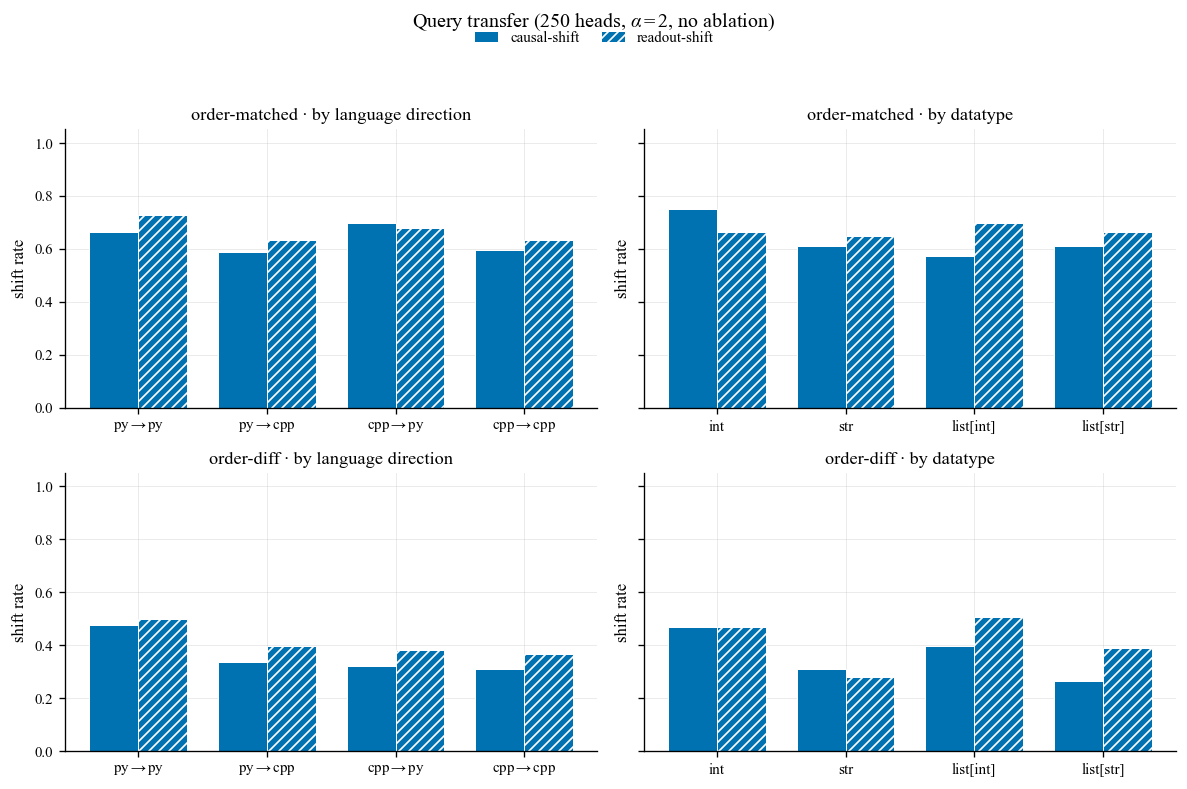

In [5]:
fig, axes = plt.subplots(2, 2, figsize=(10, 6.4), sharey=True)
rows = [('q_matched', 'order-matched'), ('q_diff', 'order-diff')]
for i, (key, title) in enumerate(rows):
    g = GRID[key]
    # left: by language-direction
    cats, c, r = mean_over(g, 'lang')
    grouped_metric_bars(axes[i][0], cats, [LANG_LBL[l] for l in cats], c, r)
    axes[i][0].set_title(f'{title} · by language direction')
    # right: by datatype
    cats, c, r = mean_over(g, 'dt')
    grouped_metric_bars(axes[i][1], cats, [DT_LBL[d] for d in cats], c, r)
    axes[i][1].set_title(f'{title} · by datatype')
fig.suptitle('Query transfer (250 heads, $\\alpha=2$, no ablation)', y=1.02, fontsize=12)
fig.tight_layout(rect=(0, 0, 1, 0.97))
# single-row legend at the top of the figure, just below the suptitle
hs = transfer_legend_handles()
fig.legend(handles=hs, labels=[h.get_label() for h in hs], loc='lower center',
           bbox_to_anchor=(0.5, 0.965), ncol=len(hs), frameon=False,
           handlelength=1.6, columnspacing=1.4, borderaxespad=0.2)
pdf = F.save_fig(fig, GROUP, 'q_barcharts'); print('saved', pdf); plt.show()

saved /disk/u/arnab/Codes/Projects/goals/notebooks/Figures/transfer/q_crosslang.pdf
Q cross-lang (order-matched & order-diff aggregated), causal / readout:
   python-python    0.570 / 0.613
   python-cpp       0.461 / 0.516
   cpp-python       0.508 / 0.531
   cpp-cpp          0.453 / 0.500
   ALL              0.498 / 0.540


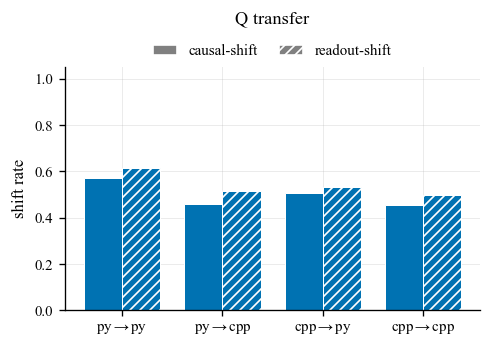

In [6]:
# Aggregated cross-lang q-transfer (mean of order-matched & order-diff) — single panel for the MAIN
# text, matching the kv cross-lang figure (Fig 5). "First column of q_barcharts, order configs averaged."
cats, cm, rm = mean_over(GRID['q_matched'], 'lang')
_,    cd, rd = mean_over(GRID['q_diff'],    'lang')
c_agg = (cm + cd) / 2; r_agg = (rm + rd) / 2
fig, ax = plt.subplots(figsize=(4.2, 3.0))
grouped_metric_bars(ax, cats, [LANG_LBL[l] for l in cats], c_agg, r_agg)
ax.set_title('Q transfer')
F.legend_top(ax, handles=F.metric_legend_handles(labels=('causal-shift', 'readout-shift')),
             labels=['causal-shift', 'readout-shift'])
fig.tight_layout()
pdf = F.save_fig(fig, GROUP, 'q_crosslang'); print('saved', pdf)
print('Q cross-lang (order-matched & order-diff aggregated), causal / readout:')
for lg, cc, rr in zip(cats, c_agg, r_agg):
    print(f'   {lg:16s} {cc:.3f} / {rr:.3f}')
print(f'   {"ALL":16s} {c_agg.mean():.3f} / {r_agg.mean():.3f}')
plt.show()

## Figure 2 — kv-transfer bar charts (`kv_barcharts`)

Left: by language-direction (mean over datatypes). Right: by datatype (mean over language-directions).

saved /disk/u/arnab/Codes/Projects/goals/notebooks/Figures/transfer/kv_barcharts.pdf


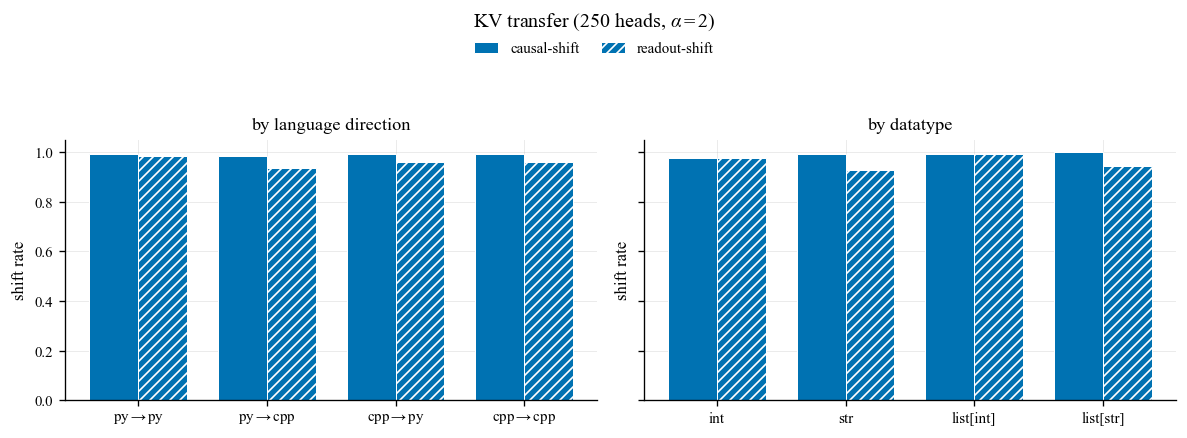

In [7]:
fig, axes = plt.subplots(1, 2, figsize=(10, 3.4), sharey=True)
g = GRID['kv']
cats, c, r = mean_over(g, 'lang')
grouped_metric_bars(axes[0], cats, [LANG_LBL[l] for l in cats], c, r)
axes[0].set_title('by language direction')
cats, c, r = mean_over(g, 'dt')
grouped_metric_bars(axes[1], cats, [DT_LBL[d] for d in cats], c, r)
axes[1].set_title('by datatype')
fig.suptitle('KV transfer (250 heads, $\\alpha=2$)', y=1.06, fontsize=12)
fig.tight_layout(rect=(0, 0, 1, 0.94))
hs = transfer_legend_handles()
fig.legend(handles=hs, labels=[h.get_label() for h in hs], loc='lower center',
           bbox_to_anchor=(0.5, 0.93), ncol=len(hs), frameon=False,
           handlelength=1.6, columnspacing=1.4, borderaxespad=0.2)
pdf = F.save_fig(fig, GROUP, 'kv_barcharts'); print('saved', pdf); plt.show()

## Figure — multi-hierarchy kv-transfer bar charts (`kv_multihier_barcharts`)

Same intervention and styling as `kv_barcharts`, one level down: the transferred goal is the *second condition* of a
two-condition list filter (`a'(x'y)` vs `a'(x'z)`), pivot = the connective (`and`/`or`, `&&`/`||`). Arm:
`kv_transfer/multi_hier/ph-goal_250__ro-goal_250__a2__pad` (goal-250, α=2, pad). Cells = 2 datatypes × 2 connectives ×
2 spec orders (match / diff) × 4 language directions, n=32 each. As in `kv_barcharts`, each bar is the mean of the cell
rates (`causal_trigger_rate`, `readout_shift_rate` over all instances). Report:
`agent_reports/claude/analysis/5.1_fig1__multi_hierarchy_kv_transfer.md`.

saved /disk/u/arnab/Codes/Projects/goals/notebooks/Figures/transfer/kv_multihier_barcharts.pdf


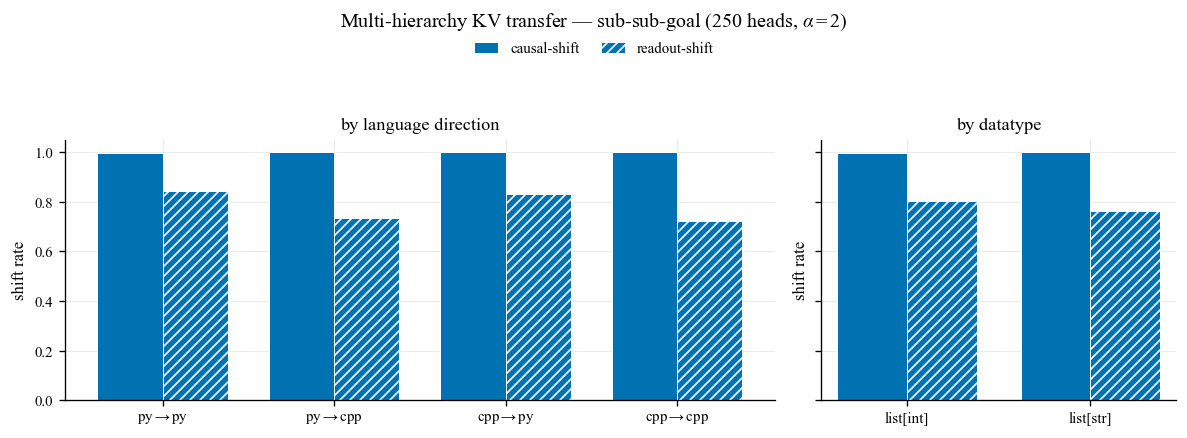

lang {'python-python': (0.996, 0.844), 'python-cpp': (1.0, 0.734), 'cpp-python': (1.0, 0.832), 'cpp-cpp': (1.0, 0.723)}
datatype {'list[int]': (0.998, 0.803), 'list[str]': (1.0, 0.764)}


In [8]:
HIER_ARM = os.path.join(DIFF, 'kv_transfer', 'multi_hier', 'ph-goal_250__ro-goal_250__a2__pad')
H_DTS, H_CONNS, H_ORDERS = ['list[int]', 'list[str]'], ['and', 'or'], ['match', 'diff']

def load_hier(dt, conn, order, lang):
    e = _read(os.path.join(HIER_ARM, f'{KV_DT[dt]}__{conn}__{order}__{lang}', 'meta.json'))
    return e['causal_trigger_rate'], e['readout_shift_rate'], e['n_instances']

HIER = {(dt, cn, od, lg): load_hier(dt, cn, od, lg)
        for dt in H_DTS for cn in H_CONNS for od in H_ORDERS for lg in LANGS}

def hier_mean(key_fn, cats):
    c = np.array([np.mean([v[0] for k, v in HIER.items() if key_fn(k) == cat]) for cat in cats])
    r = np.array([np.mean([v[1] for k, v in HIER.items() if key_fn(k) == cat]) for cat in cats])
    return c, r

fig, axes = plt.subplots(1, 2, figsize=(10, 3.4), sharey=True, gridspec_kw={'width_ratios': [2, 1]})
c, r = hier_mean(lambda k: k[3], LANGS)
grouped_metric_bars(axes[0], LANGS, [LANG_LBL[l] for l in LANGS], c, r)
axes[0].set_title('by language direction')
c, r = hier_mean(lambda k: k[0], H_DTS)
grouped_metric_bars(axes[1], H_DTS, [DT_LBL[d] for d in H_DTS], c, r)
axes[1].set_title('by datatype')
fig.suptitle('Multi-hierarchy KV transfer — sub-sub-goal (250 heads, $\\alpha=2$)', y=1.06, fontsize=12)
fig.tight_layout(rect=(0, 0, 1, 0.94))
hs = transfer_legend_handles()
fig.legend(handles=hs, labels=[h.get_label() for h in hs], loc='lower center',
           bbox_to_anchor=(0.5, 0.93), ncol=len(hs), frameon=False,
           handlelength=1.6, columnspacing=1.4, borderaxespad=0.2)
pdf = F.save_fig(fig, GROUP, 'kv_multihier_barcharts'); print('saved', pdf); plt.show()

for name, fn, cats in [('lang', lambda k: k[3], LANGS), ('datatype', lambda k: k[0], H_DTS)]:
    c, r = hier_mean(fn, cats)
    print(name, {cat: (round(float(a), 3), round(float(b), 3)) for cat, a, b in zip(cats, c, r)})

## Main-body compact panels (Fig 3 / Fig 4)

Standalone compact versions for the paper main body. NO control bars (control ≈ 0, omitted).
- `kv_right_panel` — KV causal-shift (solid) + readout-shift (white-striped) by language direction.
- `q_right_panel`  — Q causal-shift only: order-matched vs order-diff (mean over the 4×4 grid).

saved /disk/u/arnab/Codes/Projects/goals/notebooks/Figures/transfer/kv_right_panel.pdf
KV by language direction (causal / readout):
   python-python     0.992 / 0.984
   python-cpp        0.984 / 0.938
   cpp-python        0.992 / 0.961
   cpp-cpp           0.992 / 0.961


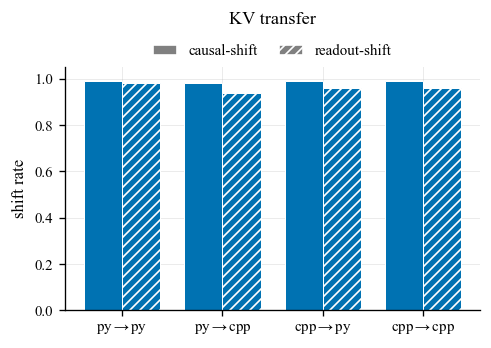

In [9]:
# --- Fig 3 (KV): causal + readout by language direction (mean over 4 datatypes) ---
cats, c, r = mean_over(GRID['kv'], 'lang')
fig, ax = plt.subplots(figsize=(4.2, 3.0))
grouped_metric_bars(ax, cats, [LANG_LBL[l] for l in cats], c, r)
ax.set_title('KV transfer')
F.legend_top(ax, handles=F.metric_legend_handles(labels=('causal-shift', 'readout-shift')),
             labels=['causal-shift', 'readout-shift'])
fig.tight_layout()
pdf = F.save_fig(fig, GROUP, 'kv_right_panel'); print('saved', pdf)
print('KV by language direction (causal / readout):')
for lg, cc, rr in zip(cats, c, r):
    print(f'   {lg:16s}  {cc:.3f} / {rr:.3f}')
plt.show()

saved /disk/u/arnab/Codes/Projects/goals/notebooks/Figures/transfer/q_right_panel.pdf
Q causal-shift by datatype (order-matched / order-diff):
   int         0.750 / 0.469
   str         0.609 / 0.312
   list[int]   0.570 / 0.398
   list[str]   0.609 / 0.266


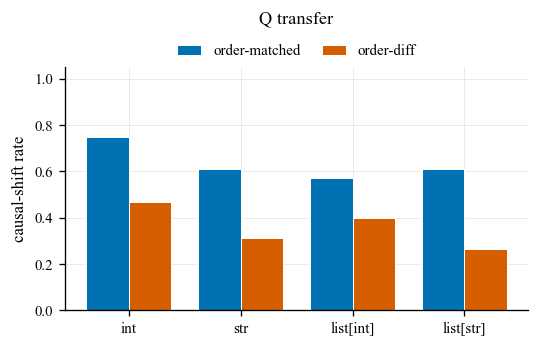

In [10]:
# --- Fig 4 (Q): causal-shift ONLY, by datatype; grouped order-matched vs order-diff ---
# per-datatype = mean causal-shift over the 4 language directions (from GRID)
cats, cm, _ = mean_over(GRID['q_matched'], 'dt')   # order-matched causal per datatype
_,    cd, _ = mean_over(GRID['q_diff'],    'dt')   # order-diff    causal per datatype
C_MATCHED, C_DIFF = COLOR, F.OKABE_ITO[1]          # blue (matched) vs orange (diff), both solid
fig, ax = plt.subplots(figsize=(4.6, 3.0))
x = np.arange(len(cats)); w = 0.38
ax.bar(x - w/2, cm, w, color=C_MATCHED, edgecolor='white', linewidth=0.6, label='order-matched')
ax.bar(x + w/2, cd, w, color=C_DIFF,    edgecolor='white', linewidth=0.6, label='order-diff')
ax.set_xticks(x); ax.set_xticklabels([DT_LBL[d] for d in cats])
ax.set_ylim(0, 1.05); ax.set_ylabel('causal-shift rate')
ax.set_title('Q transfer')
F.legend_top(ax)
fig.tight_layout()
pdf = F.save_fig(fig, GROUP, 'q_right_panel'); print('saved', pdf)
print('Q causal-shift by datatype (order-matched / order-diff):')
for d, a, b in zip(cats, cm, cd):
    print(f'   {d:10s}  {a:.3f} / {b:.3f}')
plt.show()

## Tables — 4×4 datatype × language-direction grids

Each cell is `causal-shift / readout-shift`. Emits `.tex` (via `save_table`) and previews with
`render_latex_table` (falls back to a rich table).

In [11]:
def grid_tex(key, caption, label):
    g = GRID[key]
    head = ('\\begin{tabular}{lcccc}\n\\toprule\n'
            '& \\multicolumn{4}{c}{causal-shift / readout-shift} \\\\\n'
            '\\cmidrule(lr){2-5}\n'
            'datatype & py$\\to$py & py$\\to$cpp & cpp$\\to$py & cpp$\\to$cpp \\\\\n\\midrule\n')
    body = []
    dt_tex = {'int':'\\texttt{int}','str':'\\texttt{str}',
              'list[int]':'\\texttt{list[int]}','list[str]':'\\texttt{list[str]}'}
    for dt in DTS:
        cells_ = ' & '.join(f'{g[dt][lg][0]:.2f} / {g[dt][lg][1]:.2f}' for lg in LANGS)
        body.append(f'{dt_tex[dt]} & {cells_} \\\\')
    tail = ('\n\\bottomrule\n\\end{tabular}')
    tabular = head + '\n'.join(body) + tail
    tex = ('\\begin{table}[ht]\\centering\\small\n' + tabular +
           f'\n\\caption{{{caption}}}\n\\label{{{label}}}\n\\end{{table}}')
    return tabular, tex

def show_table(key, name, caption, label):
    tabular, tex = grid_tex(key, caption, label)
    path = F.save_table(tex, GROUP, name); print('wrote', path)
    g = GRID[key]
    t = Table(title=caption.split('}')[0].replace('\\textbf{',''))
    t.add_column('datatype')
    for lg in LANGS: t.add_column(LANG_LBL[lg].replace('$\\to$','->'), justify='right')
    for dt in DTS:
        t.add_row(dt, *[f'{g[dt][lg][0]:.2f}/{g[dt][lg][1]:.2f}' for lg in LANGS])
    rich_print(t)
    img = F.render_latex_table(tabular)
    return img

wrote /disk/u/arnab/Codes/Projects/goals/notebooks/Figures/transfer/kv_grid.tex


                   KV transfer full grid                    
┏━━━━━━━━━━┳━━━━━━━━━━━┳━━━━━━━━━━━┳━━━━━━━━━━━┳━━━━━━━━━━━┓
┃ datatype ┃    py->py ┃   py->cpp ┃   cpp->py ┃  cpp->cpp ┃
┡━━━━━━━━━━╇━━━━━━━━━━━╇━━━━━━━━━━━╇━━━━━━━━━━━╇━━━━━━━━━━━┩
│ int      │ 1.00/0.97 │ 0.94/0.97 │ 1.00/1.00 │ 0.97/0.97 │
│ str      │ 1.00/0.97 │ 1.00/0.94 │ 0.97/0.91 │ 1.00/0.91 │
│ list     │ 0.97/1.00 │ 1.00/0.97 │ 1.00/1.00 │ 1.00/1.00 │
│ list     │ 1.00/1.00 │ 1.00/0.88 │ 1.00/0.94 │ 1.00/0.97 │
└──────────┴───────────┴───────────┴───────────┴───────────┘

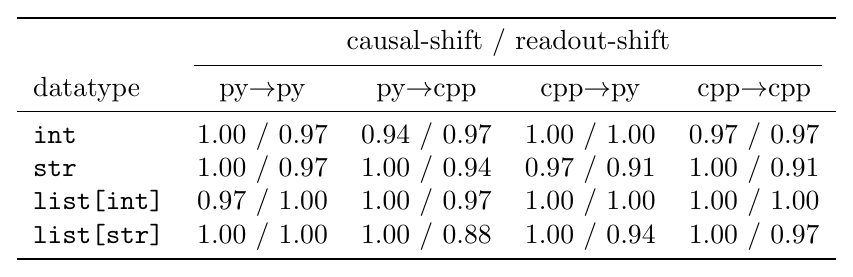

In [12]:
img = show_table('kv', 'kv_grid',
    r'\textbf{KV transfer full grid} (causal-shift / readout-shift).', 'tab:kv-grid')
img

wrote /disk/u/arnab/Codes/Projects/goals/notebooks/Figures/transfer/q_matched.tex


               Query transfer, order-matched                
┏━━━━━━━━━━┳━━━━━━━━━━━┳━━━━━━━━━━━┳━━━━━━━━━━━┳━━━━━━━━━━━┓
┃ datatype ┃    py->py ┃   py->cpp ┃   cpp->py ┃  cpp->cpp ┃
┡━━━━━━━━━━╇━━━━━━━━━━━╇━━━━━━━━━━━╇━━━━━━━━━━━╇━━━━━━━━━━━┩
│ int      │ 0.72/0.69 │ 0.75/0.72 │ 0.69/0.56 │ 0.84/0.69 │
│ str      │ 0.62/0.75 │ 0.59/0.56 │ 0.72/0.72 │ 0.50/0.56 │
│ list     │ 0.59/0.69 │ 0.44/0.66 │ 0.66/0.75 │ 0.59/0.69 │
│ list     │ 0.72/0.78 │ 0.56/0.59 │ 0.72/0.69 │ 0.44/0.59 │
└──────────┴───────────┴───────────┴───────────┴───────────┘

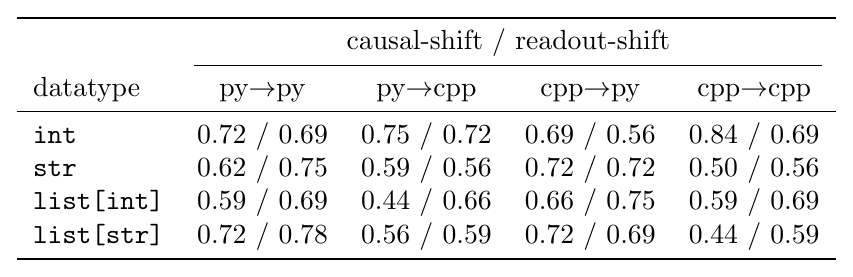

In [13]:
img = show_table('q_matched', 'q_matched',
    r'\textbf{Query transfer, order-matched} (causal-shift / readout-shift).', 'tab:q-matched')
img

wrote /disk/u/arnab/Codes/Projects/goals/notebooks/Figures/transfer/q_diff.tex


                 Query transfer, order-diff                 
┏━━━━━━━━━━┳━━━━━━━━━━━┳━━━━━━━━━━━┳━━━━━━━━━━━┳━━━━━━━━━━━┓
┃ datatype ┃    py->py ┃   py->cpp ┃   cpp->py ┃  cpp->cpp ┃
┡━━━━━━━━━━╇━━━━━━━━━━━╇━━━━━━━━━━━╇━━━━━━━━━━━╇━━━━━━━━━━━┩
│ int      │ 0.59/0.53 │ 0.56/0.50 │ 0.31/0.38 │ 0.41/0.47 │
│ str      │ 0.44/0.34 │ 0.31/0.28 │ 0.25/0.31 │ 0.25/0.19 │
│ list     │ 0.50/0.66 │ 0.28/0.38 │ 0.44/0.53 │ 0.38/0.47 │
│ list     │ 0.38/0.47 │ 0.19/0.44 │ 0.28/0.31 │ 0.22/0.34 │
└──────────┴───────────┴───────────┴───────────┴───────────┘

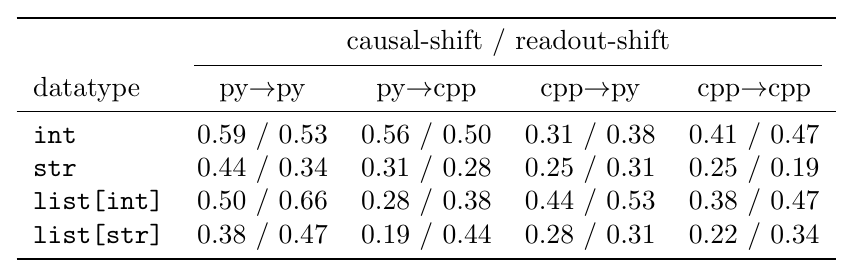

In [14]:
img = show_table('q_diff', 'q_diff',
    r'\textbf{Query transfer, order-diff} (causal-shift / readout-shift).', 'tab:q-diff')
img

## Aggregate numbers per language direction (for the report)

In [15]:
for key, title in [('kv','kv-transfer'),('q_matched','q order-matched'),('q_diff','q order-diff')]:
    g = GRID[key]; oc, orr = overall(g)
    print(f'=== {title} ===  overall causal-shift={oc:.3f}  readout-shift={orr:.3f}')
    cats, c, r = mean_over(g, 'lang')
    for lg, cc, rr in zip(cats, c, r):
        print(f'   {lg:16s}  causal={cc:.3f}  readout={rr:.3f}')

=== kv-transfer ===  overall causal-shift=0.990  readout-shift=0.961
   python-python     causal=0.992  readout=0.984
   python-cpp        causal=0.984  readout=0.938
   cpp-python        causal=0.992  readout=0.961
   cpp-cpp           causal=0.992  readout=0.961
=== q order-matched ===  overall causal-shift=0.635  readout-shift=0.668
   python-python     causal=0.664  readout=0.727
   python-cpp        causal=0.586  readout=0.633
   cpp-python        causal=0.695  readout=0.680
   cpp-cpp           causal=0.594  readout=0.633
=== q order-diff ===  overall causal-shift=0.361  readout-shift=0.412
   python-python     causal=0.477  readout=0.500
   python-cpp        causal=0.336  readout=0.398
   cpp-python        causal=0.320  readout=0.383
   cpp-cpp           causal=0.312  readout=0.367
